<a href="https://colab.research.google.com/github/thamarai-design/Mini-Project-2/blob/main/Online_food_delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Step 1: Data Collection

In [10]:
pip install sqlalchemy pymysql

In [1]:
import pandas as pd
import numpy as np

# Load the dataset from your local Colab session storage
df = pd.read_csv("Online_food_Delivery_Dataset.csv")

# 1. Inspect the basic structure and shape
print("Dataset Shape:", df.shape)
print("\n--- Column Info ---")
print(df.info())

# 2. Check for missing values across columns
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# 3. View the first few rows
df.head()

Dataset Shape: (100000, 25)

--- Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  object 
 1   Customer_ID          100000 non-null  object 
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   object 
 4   City                 83274 non-null   object 
 5   Area                 83315 non-null   object 
 6   Restaurant_ID        100000 non-null  object 
 7   Restaurant_Name      100000 non-null  object 
 8   Cuisine_Type         83115 non-null   object 
 9   Order_Date           98986 non-null   object 
 10  Order_Time           98002 non-null   object 
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied    

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12


Step 3: Data Cleaning & Preprocessing


In [4]:
# 1. Handle Missing Values
# Impute numerical columns with median or mean
df['Customer_Age'] = df['Customer_Age'].fillna(df['Customer_Age'].median())
df['Delivery_Time_Min'] = df['Delivery_Time_Min'].fillna(df['Delivery_Time_Min'].median())
df['Distance_km'] = df['Distance_km'].fillna(df['Distance_km'].median())
df['Order_Value'] = df['Order_Value'].fillna(df['Order_Value'].median())
df['Discount_Applied'] = df['Discount_Applied'].fillna(0) # Assuming NaN discount means 0
df['Final_Amount'] = df['Final_Amount'].fillna(df['Order_Value'] - df['Discount_Applied'])
df['Delivery_Rating'] = df['Delivery_Rating'].fillna(df['Delivery_Rating'].median())

# Impute categorical columns with mode or a default placeholder
df['Customer_Gender'] = df['Customer_Gender'].fillna('Unknown')
df['City'] = df['City'].fillna('Unknown')
df['Area'] = df['Area'].fillna('Unknown')
df['Cuisine_Type'] = df['Cuisine_Type'].fillna('Mixed')
df['Payment_Mode'] = df['Payment_Mode'].fillna('Cash')
df['Peak_Hour'] = df['Peak_Hour'].fillna(False)
df['Cancellation_Reason'] = df['Cancellation_Reason'].fillna('None')

# 2. Correct Inconsistencies & Invalid Values
# Ensure ratings are capped between 1 and 5
df['Delivery_Rating'] = df['Delivery_Rating'].clip(1, 5)
df['Restaurant_Rating'] = df['Restaurant_Rating'].clip(1, 5)

# Ensure no negative profit margins or order values if any exist
df['Order_Value'] = df['Order_Value'].abs()
df['Distance_km'] = df['Distance_km'].abs()

# Verify missing values are cleared
print("--- Missing Values After Cleaning ---")
print(df.isnull().sum().sum()) # Should be 0 or minimal for date/time fields if kept as strings

--- Missing Values After Cleaning ---
3012


Step 4: Exploratory Data Analysis (EDA)


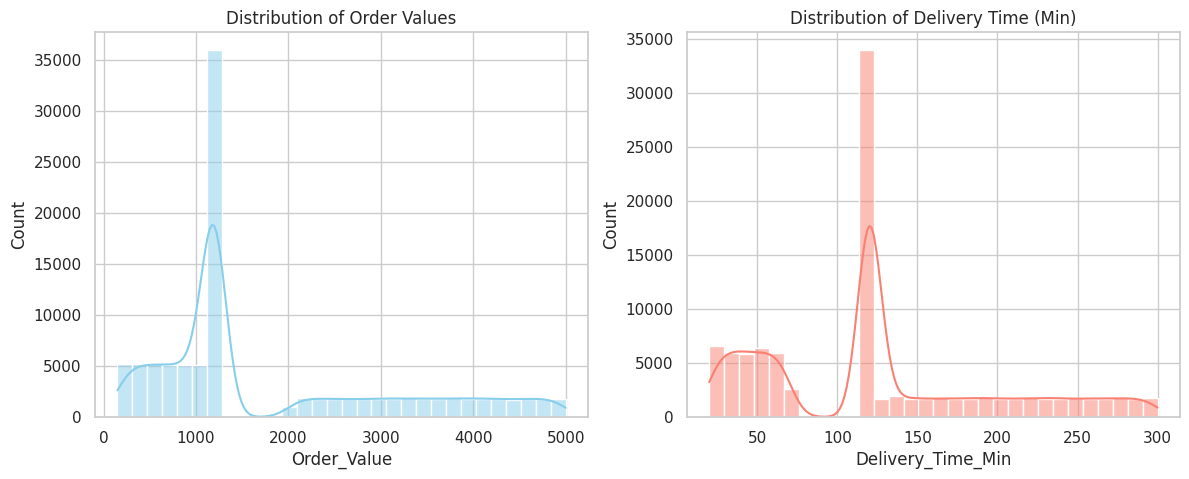

/tmp/ipykernel_3115/962703649.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='City', order=df['City'].value_counts().index, ax=axes[0], palette='viridis')
/tmp/ipykernel_3115/962703649.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Cuisine_Type', order=df['Cuisine_Type'].value_counts().index, ax=axes[1], palette='magma')


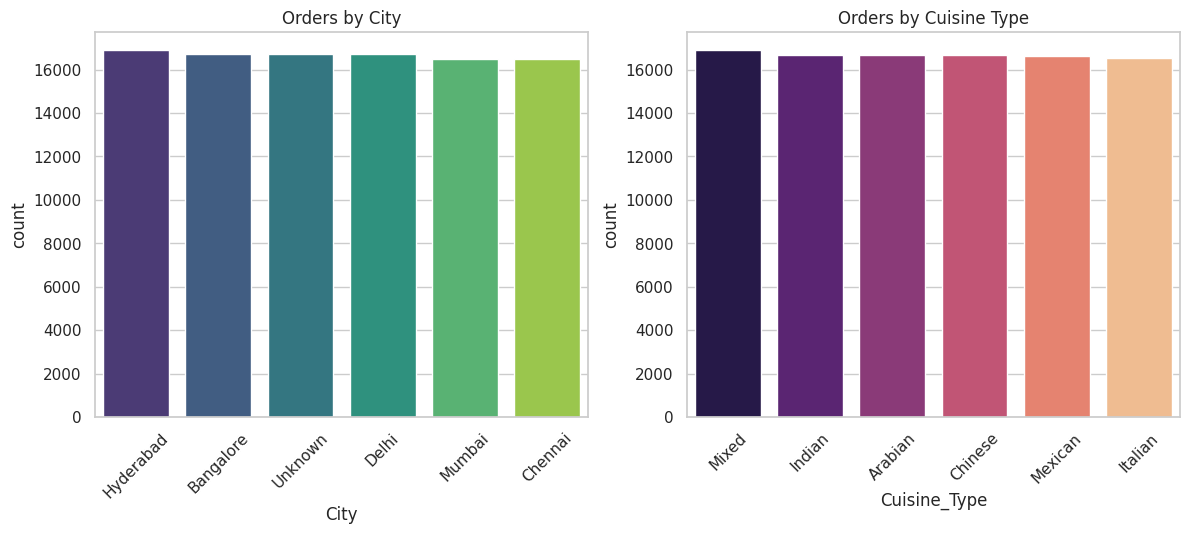

/tmp/ipykernel_3115/962703649.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Order_Day', palette='Set2')


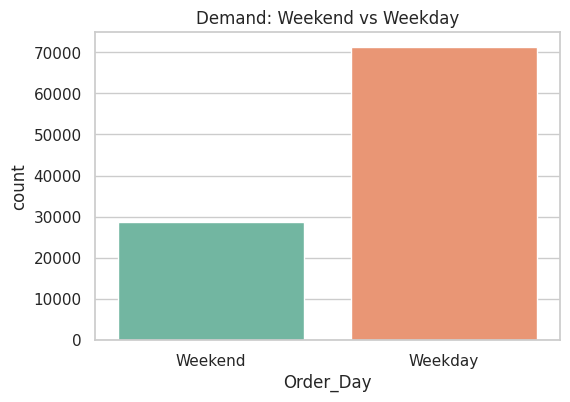

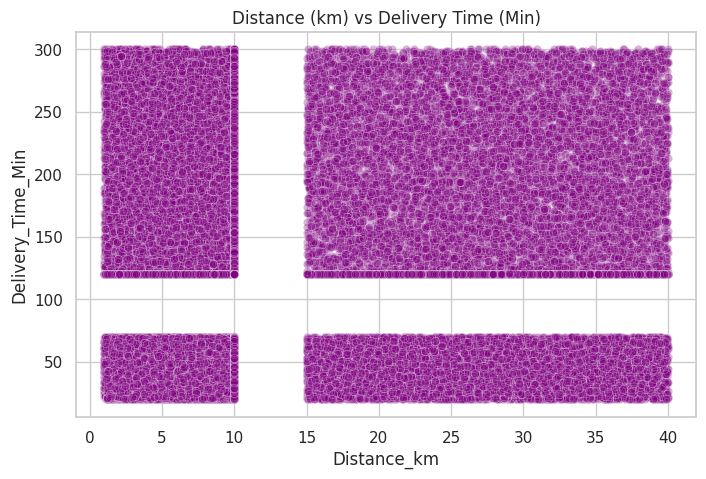

/tmp/ipykernel_3115/962703649.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Cancellation_Reason', order=df['Cancellation_Reason'].value_counts().index, palette='coolwarm')


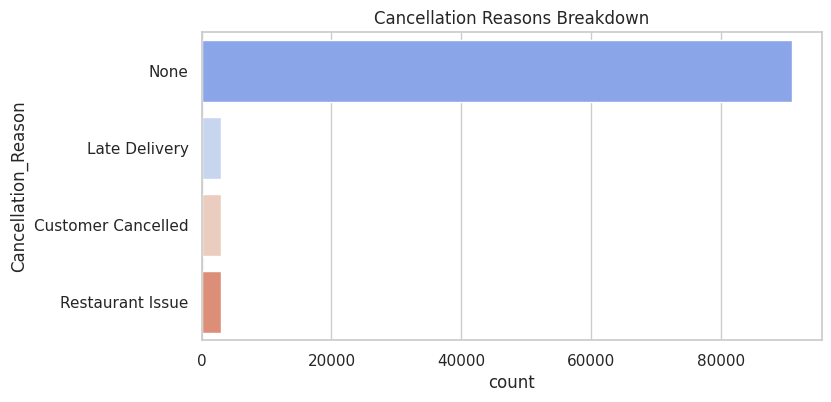

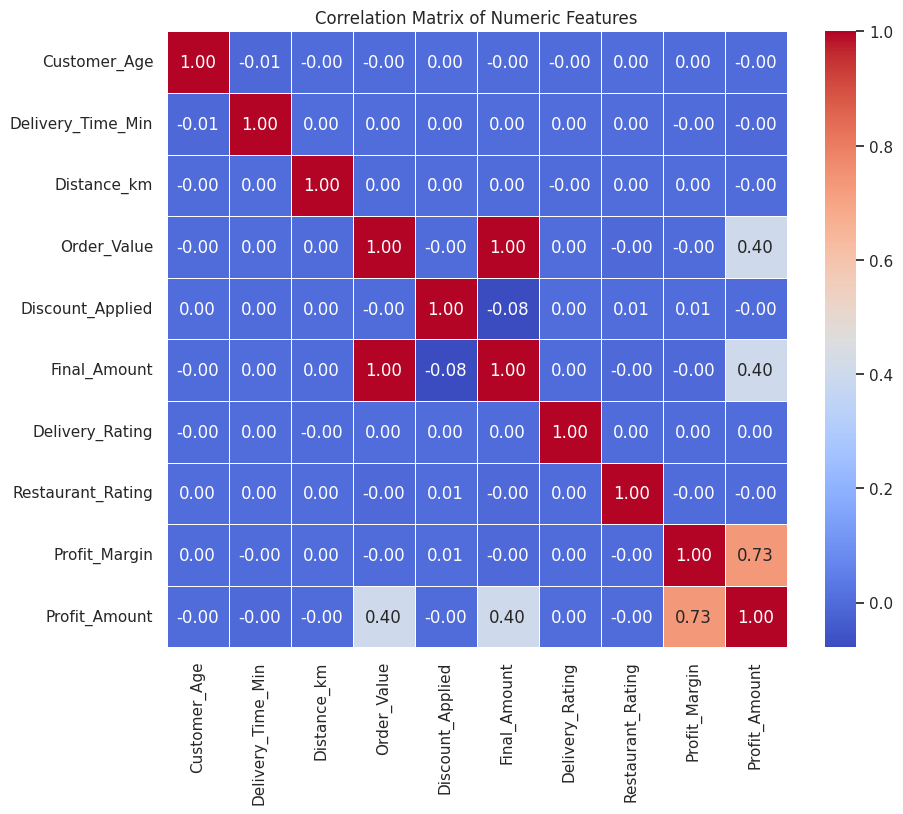

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Distribution of Order Values and Delivery Time
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Order_Value'].dropna(), bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Order Values')

sns.histplot(df['Delivery_Time_Min'].dropna(), bins=30, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Delivery Time (Min)')
plt.show()

# 2. City-wise and Cuisine-wise Order Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='City', order=df['City'].value_counts().index, ax=axes[0], palette='viridis')
axes[0].set_title('Orders by City')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='Cuisine_Type', order=df['Cuisine_Type'].value_counts().index, ax=axes[1], palette='magma')
axes[1].set_title('Orders by Cuisine Type')
axes[1].tick_params(axis='x', rotation=45)
plt.show()

# 3. Weekend vs Weekday Demand
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Order_Day', palette='Set2')
plt.title('Demand: Weekend vs Weekday')
plt.show()

# 4. Distance vs Delivery Time Relationship
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Distance_km', y='Delivery_Time_Min', alpha=0.3, color='purple')
plt.title('Distance (km) vs Delivery Time (Min)')
plt.show()

# 5. Cancellation Reasons Analysis
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='Cancellation_Reason', order=df['Cancellation_Reason'].value_counts().index, palette='coolwarm')
plt.title('Cancellation Reasons Breakdown')
plt.show()

# 6. Correlation Analysis among Numeric Features
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_cols.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

 Step 5: Feature Engineering

In [8]:
# 1. Order Day Type (Already exists in dataset as 'Order_Day' - Weekday / Weekend, but let's ensure it's standardized)
df['Order_Day_Type'] = df['Order_Day'].apply(lambda x: 'Weekend' if str(x).lower() == 'weekend' else 'Weekday')

# 2. Peak Hour Indicator (Convert or verify boolean/binary indicator)
# If 'Peak_Hour' is boolean/object, map it cleanly
df['Peak_Hour_Indicator'] = df['Peak_Hour'].apply(lambda x: 'Peak' if x == True or str(x).lower() == 'true' else 'Non-Peak')

# 3. Profit Margin Percentage (Extract or compute percentage representation)
# Profit_Margin is already present as a float, let's create a percentage column
df['Profit_Margin_Pct'] = df['Profit_Margin'] * 100

# 4. Delivery Performance Categories (Categorize based on Delivery_Time_Min)
# Define bins/labels for delivery speed categories
bins_time = [0, 30, 60, 120, float('inf')]
labels_time = ['Fast (<30m)', 'Moderate (30-60m)', 'Delayed (1-2h)', 'Severely Delayed (>2h)']
df['Delivery_Performance_Category'] = pd.cut(df['Delivery_Time_Min'], bins=bins_time, labels=labels_time, right=False)

# 5. Customer Age Groups (Categorize based on Customer_Age)
bins_age = [0, 25, 35, 50, 100]
labels_age = ['Young Adult (<=25)', 'Adult (26-35)', 'Middle-Aged (36-50)', 'Senior (>50)']
df['Customer_Age_Group'] = pd.cut(df['Customer_Age'], bins=bins_age, labels=labels_age, right=False)

# Verify the newly engineered features
print("--- Newly Engineered Features Sample ---")
print(df[['Customer_Age', 'Customer_Age_Group', 'Delivery_Time_Min', 'Delivery_Performance_Category', 'Profit_Margin_Pct']].head(10))

--- Newly Engineered Features Sample ---
   Customer_Age   Customer_Age_Group  Delivery_Time_Min  \
0          19.0   Young Adult (<=25)              187.0   
1          39.0  Middle-Aged (36-50)               20.0   
2          39.0  Middle-Aged (36-50)              207.0   
3          39.0  Middle-Aged (36-50)              143.0   
4          57.0         Senior (>50)               51.0   
5          37.0  Middle-Aged (36-50)               56.0   
6          40.0  Middle-Aged (36-50)              273.0   
7          39.0  Middle-Aged (36-50)              120.0   
8          39.0  Middle-Aged (36-50)              120.0   
9          39.0  Middle-Aged (36-50)              120.0   

  Delivery_Performance_Category  Profit_Margin_Pct  
0        Severely Delayed (>2h)               13.0  
1                   Fast (<30m)               48.0  
2        Severely Delayed (>2h)                8.0  
3        Severely Delayed (>2h)                4.0  
4             Moderate (30-60m)             

Exploratory Data Analysis (EDA) &
 Feature Engineering

In [5]:
# 1. Feature Engineering: Create Order Day Type & Profit Margin categories if needed
df['Profit_Amount'] = df['Order_Value'] * df['Profit_Margin']

# 2. EDA: Check top-spending cities by total final amount
print("--- Top Cities by Revenue ---")
print(df.groupby('City')['Final_Amount'].sum().sort_values(ascending=False))

# 3. EDA: Delivery performance summary
print("\n--- Average Delivery Time by City ---")
print(df.groupby('City')['Delivery_Time_Min'].mean())

# 4. EDA: Cancellation reasons breakdown
print("\n--- Cancellation Reasons Breakdown ---")
print(df['Cancellation_Reason'].value_counts())

--- Top Cities by Revenue ---
City
Bangalore    28778569.0
Hyderabad    28667179.0
Unknown      28629540.0
Delhi        28387836.0
Chennai      28265531.0
Mumbai       28142144.0
Name: Final_Amount, dtype: float64

--- Average Delivery Time by City ---
City
Bangalore    124.373297
Chennai      124.549423
Delhi        124.896376
Hyderabad    125.031805
Mumbai       125.937246
Unknown      125.110307
Name: Delivery_Time_Min, dtype: float64

--- Cancellation Reasons Breakdown ---
Cancellation_Reason
None                  90969
Late Delivery          3059
Customer Cancelled     2993
Restaurant Issue       2979
Name: count, dtype: int64


Step 6: Data Storage (MySQL)

In [12]:
import sqlite3

# 1. Create a connection to an in-memory or local SQLite database file in Colab
conn = sqlite3.connect('food_delivery.db')

# 2. Store your cleaned DataFrame into a SQLite table named 'food_orders'
table_name = "food_orders"
df.to_sql(name=table_name, con=conn, if_exists='replace', index=False)

print(f"Successfully loaded {len(df)} rows into the SQLite table '{table_name}'!")

# 3. Test running a sample SQL query directly in Colab
query = "SELECT City, COUNT(*) AS Total_Orders FROM food_orders GROUP BY City"
result_df = pd.read_sql(query, con=conn)
print("\n--- Sample Query Result ---")
print(result_df)

# Close the connection when done
conn.close()

Successfully loaded 100000 rows into the SQLite table 'food_orders'!

--- Sample Query Result ---
        City  Total_Orders
0  Bangalore         16732
1    Chennai         16470
2      Delhi         16695
3  Hyderabad         16884
4     Mumbai         16493
5    Unknown         16726


Analyst Tasks (EDA & Analytics)


In [26]:
# Connect to your SQLite database created in Step 6
conn = sqlite3.connect('food_delivery.db')

# --- 1. CUSTOMER & ORDER ANALYSIS ---
print("=== 1. CUSTOMER & ORDER ANALYSIS ===")

# Task 1: Identify top-spending customers
q1 = """
    SELECT Customer_ID, SUM(Final_Amount) AS Total_Spent
    FROM food_orders
    GROUP BY Customer_ID
    ORDER BY Total_Spent DESC
    LIMIT 5;
"""
print("Top Spending Customers:\n", pd.read_sql(q1, conn), "\n")

# Task 2: Analyze age group vs order value
q2 = """
    SELECT Customer_Age_Group, AVG(Order_Value) AS Avg_Order_Value, COUNT(*) AS Total_Orders
    FROM food_orders
    GROUP BY Customer_Age_Group;
"""
print("Age Group vs Order Value:\n", pd.read_sql(q2, conn), "\n")

# Task 3: Weekend vs Weekday order patterns
q3 = """
    SELECT Order_Day_Type, COUNT(*) AS Total_Orders, AVG(Final_Amount) AS Avg_Spent
    FROM food_orders
    GROUP BY Order_Day_Type;
"""
print("Weekend vs Weekday Orders:\n", pd.read_sql(q3, conn), "\n")


# --- 2. REVENUE & PROFIT ANALYSIS ---
print("=== 2. REVENUE & PROFIT ANALYSIS ===")

# Task 4: Monthly revenue trends
print("Monthly Revenue Trends:")
# Convert Order_Date to datetime, extract month number and month name, then group & sort
df_orders['Parsed_Date'] = pd.to_datetime(df_orders['Order_Date'], errors='coerce')
df_orders['Month_Num'] = df_orders['Parsed_Date'].dt.month
df_orders['Month_Name'] = df_orders['Parsed_Date'].dt.strftime('%B')

monthly_trend = df_orders.groupby(['Month_Num', 'Month_Name']).agg(
    Total_Monthly_Revenue=('Final_Amount', 'sum'),
    Total_Orders=('Order_ID', 'count')
).reset_index().sort_values('Month_Num')

# Display result
print(monthly_trend[['Month_Name', 'Total_Monthly_Revenue', 'Total_Orders']])

# Task 5: High-revenue cities and cuisines
q5 = """
    SELECT City, Cuisine_Type, SUM(Final_Amount) AS Total_Revenue
    FROM food_orders
    GROUP BY City, Cuisine_Type
    ORDER BY Total_Revenue DESC
    LIMIT 5;
"""
print("\nTop Cities & Cuisines by Revenue:\n", pd.read_sql(q5, conn), "\n")

# Task 6: Impact of discounts on profit amount
q6 = """
    SELECT
        CASE WHEN Discount_Applied > 0 THEN 'Discount Given' ELSE 'No Discount' END AS Discount_Status,
        AVG(Profit_Amount) AS Avg_Profit,
        AVG(Final_Amount) AS Avg_Final_Amount
    FROM food_orders
    GROUP BY Discount_Status;
"""
print("Impact of Discounts on Profit:\n", pd.read_sql(q6, conn), "\n")


# --- 3. DELIVERY PERFORMANCE ---
print("=== 3. DELIVERY PERFORMANCE ===")

# Task 7: Average delivery time by city
q7 = """
    SELECT City, AVG(Delivery_Time_Min) AS Avg_Delivery_Time, AVG(Distance_km) AS Avg_Distance
    FROM food_orders
    GROUP BY City;
"""
print("Average Delivery Time by City:\n", pd.read_sql(q7, conn), "\n")

# Task 8: Distance vs delivery delay analysis
q8 = """
    SELECT ROUND(Distance_km, 1) AS Distance_Rounded,
           AVG(Delivery_Time_Min) AS Avg_Delivery_Time,
           COUNT(*) AS Order_Count
    FROM food_orders
    WHERE Distance_km IS NOT NULL AND Delivery_Time_Min IS NOT NULL
    GROUP BY Distance_Rounded
    ORDER BY Distance_Rounded;
"""
print("Distance vs Delivery Time:\n", pd.read_sql(q8, conn), "\n")

# Task 9: Delivery rating vs delivery time
q9 = """
    SELECT Delivery_Rating, AVG(Delivery_Time_Min) AS Avg_Delivery_Time
    FROM food_orders
    WHERE Delivery_Rating IS NOT NULL
    GROUP BY Delivery_Rating
    ORDER BY Delivery_Rating DESC;
"""
print("Delivery Rating vs Delivery Time:\n", pd.read_sql(q9, conn), "\n")


# --- 4. RESTAURANT PERFORMANCE ---
print("=== 4. RESTAURANT PERFORMANCE ===")

# Task 10: Top-rated restaurants
q10 = """
    SELECT Restaurant_Name, Restaurant_Rating, COUNT(*) AS Total_Orders
    FROM food_orders
    GROUP BY Restaurant_Name, Restaurant_Rating
    ORDER BY Restaurant_Rating DESC, Total_Orders DESC
    LIMIT 5;
"""
print("Top-Rated Restaurants:\n", pd.read_sql(q10, conn), "\n")

# Task 11: Cancellation rate by restaurant
q11 = """
    SELECT Restaurant_Name,
           COUNT(*) AS Total_Orders,
           SUM(CASE WHEN Order_Status = 'Cancelled' THEN 1 ELSE 0 END) AS Cancelled_Orders,
           (CAST(SUM(CASE WHEN Order_Status = 'Cancelled' THEN 1 ELSE 0 END) AS REAL) / COUNT(*)) * 100 AS Cancellation_Rate_Pct
    FROM food_orders
    GROUP BY Restaurant_Name
    ORDER BY Cancellation_Rate_Pct DESC
    LIMIT 5;
"""
print("Restaurants with Highest Cancellation Rates:\n", pd.read_sql(q11, conn), "\n")

# Task 12: Cuisine-wise performance
q12 = """
    SELECT Cuisine_Type,
           COUNT(*) AS Total_Orders,
           AVG(Restaurant_Rating) AS Avg_Restaurant_Rating,
           SUM(Final_Amount) AS Total_Revenue,
           AVG(Profit_Margin_Pct) AS Avg_Profit_Margin_Pct
    FROM food_orders
    WHERE Cuisine_Type IS NOT NULL
    GROUP BY Cuisine_Type
    ORDER BY Total_Revenue DESC;
"""
print("Cuisine-wise Performance:\n", pd.read_sql(q12, conn), "\n")


# --- 5. OPERATIONAL INSIGHTS ---
print("=== 5. OPERATIONAL INSIGHTS ===")

# Task 13: Peak hour demand analysis
q13 = """
    SELECT Peak_Hour_Indicator, COUNT(*) AS Order_Count, AVG(Delivery_Time_Min) AS Avg_Delivery_Time
    FROM food_orders
    GROUP BY Peak_Hour_Indicator;
"""
print("Peak Hour Demand Analysis:\n", pd.read_sql(q13, conn), "\n")

# Task 14: Payment mode preferences
q14 = """
    SELECT Payment_Mode, COUNT(*) AS Usage_Count, SUM(Final_Amount) AS Total_Volume
    FROM food_orders
    GROUP BY Payment_Mode
    ORDER BY Usage_Count DESC;
"""
print("Payment Mode Preferences:\n", pd.read_sql(q14, conn), "\n")

# Task 15:Cancellation reason analysis
q15 = """
    SELECT Cancellation_Reason,
           COUNT(*) AS Cancellation_Count,
           ROUND((CAST(COUNT(*) AS REAL) / (SELECT COUNT(*) FROM food_orders WHERE Order_Status = 'Cancelled')) * 100, 2) AS Percentage_Of_Cancellations
    FROM food_orders
    WHERE Order_Status = 'Cancelled'
    GROUP BY Cancellation_Reason
    ORDER BY Cancellation_Count DESC;
"""
print("Cancellation Reason Analysis:\n", pd.read_sql(q15, conn), "\n")

# Close the database connection
conn.close()

=== 1. CUSTOMER & ORDER ANALYSIS ===
Top Spending Customers:
   Customer_ID  Total_Spent
0    CUST5267      51977.0
1    CUST1606      51371.0
2    CUST6706      47539.0
3    CUST6252      46025.0
4    CUST5534      45368.0 

Age Group vs Order Value:
     Customer_Age_Group  Avg_Order_Value  Total_Orders
0        Adult (26-35)      1803.053688         11660
1  Middle-Aged (36-50)      1784.635272         67601
2         Senior (>50)      1784.317226         12644
3   Young Adult (<=25)      1787.107721          8095 

Weekend vs Weekday Orders:
   Order_Day_Type  Total_Orders    Avg_Spent
0        Weekday         71370  1711.371150
1        Weekend         28630  1702.069158 

=== 2. REVENUE & PROFIT ANALYSIS ===
Monthly Revenue Trends:
   Month_Name  Total_Monthly_Revenue  Total_Orders
0     January             14553250.0          8508
1    February             13468861.0          7921
2       March             14254415.0          8417
3       April             13835930.0          81

In [22]:
import sqlite3
import pandas as pd



   Month_Name  Total_Monthly_Revenue  Total_Orders
0     January             14553250.0          8508
1    February             13468861.0          7921
2       March             14254415.0          8417
3       April             13835930.0          8115
4         May             14279317.0          8350
5        June             14017850.0          8180
6        July             14715316.0          8513
7      August             14117629.0          8261
8   September             14159660.0          8183
9     October             14077108.0          8306
10   November             13921948.0          8182
11   December             13747933.0          8050


The Dashboard - Power BI

In [28]:
# Connect to your SQLite database
conn = sqlite3.connect('food_delivery.db')

# Query to calculate all 7 Power BI Dashboard KPIs
dashboard_query = """
    SELECT
        COUNT(Order_ID) AS Total_Orders,
        ROUND(SUM(Final_Amount), 2) AS Total_Revenue,
        ROUND(AVG(Final_Amount), 2) AS Average_Order_Value,
        ROUND(AVG(Delivery_Time_Min), 2) AS Average_Delivery_Time,
        ROUND((CAST(SUM(CASE WHEN Order_Status = 'Cancelled' THEN 1 ELSE 0 END) AS REAL) / COUNT(Order_ID)) * 100, 2) AS Cancellation_Rate_Pct,
        ROUND(AVG(Delivery_Rating), 2) AS Average_Delivery_Rating,
        ROUND(AVG(Profit_Margin_Pct), 2) AS Avg_Profit_Margin_Pct
    FROM food_orders;
"""

kpi_df = pd.read_sql(dashboard_query, conn)
conn.close()

# Display the KPIs for your dashboard cards
print("=== POWER BI / STREAMLIT DASHBOARD KPIs ===")
for col in kpi_df.columns:
    print(f"{col}: {kpi_df[col].values[0]}")

=== POWER BI / STREAMLIT DASHBOARD KPIs ===
Total_Orders: 100000
Total_Revenue: 170870799.0
Average_Order_Value: 1708.71
Average_Delivery_Time: 124.98
Cancellation_Rate_Pct: 15.04
Average_Delivery_Rating: 2.99
Avg_Profit_Margin_Pct: 15.04
